# Metadata model comparison Subset

## Summary

- Four easy-to-explain metadata methods are compared: a prevalence dummy, unweighted logistic regression, random forest, and XGBoost.
- Every prediction is out-of-fold using the same five patient-safe folds from `train_folds.csv`.
- Random forest gives the strongest overall result, with **0.606 ROC-AUC** and **0.0443 average precision**, but its improvement over logistic regression is small.
- XGBoost reaches **0.0439 average precision** but does not improve ROC-AUC, so additional model complexity is not clearly rewarded by these metadata features.
- The labelled subset test set is not loaded or evaluated in this notebook.


## Context & Methods

This comparison asks whether the available non-image metadata provides useful discrimination before image modelling. Sex, five-year age bucket, and anatomical site are one-hot encoded inside each training fold, then evaluated with linear and tree-based classifiers.

### Key assumptions

- The prediction target is image-level malignancy (`target`).
- `diagnosis` and `benign_malignant` are excluded because they reveal the outcome. Identifiers and `fold` are also excluded.
- Model selection uses only the five patient-safe training folds. The subset test labels remain reserved for final evaluation.
- ROC-AUC measures ranking across both classes. Average precision is the primary imbalance-aware summary and should be read against the 1.86% positive prevalence.
- Log loss and Brier score assess probability quality; lower values are better.
- Coefficients describe associations in this dataset and are not causal or clinically validated.


## Data

### Set Paths


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SOURCE_DIR = PROJECT_ROOT / "src"
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from melanoma_detection.metadata_model import (
    DEFAULT_METADATA_FEATURES,
    binary_probability_metrics,
    build_logistic_metadata_pipeline,
    build_random_forest_metadata_pipeline,
    build_xgboost_metadata_pipeline,
    generate_oof_probabilities,
)

TRAIN_FOLDS_PATH = PROJECT_ROOT / "data" / "subset" / "processed" / "train_folds.csv"
OOF_PATH = PROJECT_ROOT / "results" / "tables" / "metadata_oof_predictions_d1.csv"
COEFFICIENTS_PATH = PROJECT_ROOT / "results" / "tables" / "metadata_logistic_coefficients_d1.csv"
METRICS_PATH = PROJECT_ROOT / "results" / "metrics" / "metadata_baseline_metrics_d1.csv"
CURVES_PATH = PROJECT_ROOT / "results" / "figures" / "metadata_baseline_curves_d1.png"

FEATURE_COLUMNS = list(DEFAULT_METADATA_FEATURES)
MODEL_LABELS = {
    "dummy": "Prevalence dummy",
    "logistic": "Logistic regression",
    "random_forest": "Random forest",
    "xgboost": "XGBoost",
}

print(f"Training folds: {TRAIN_FOLDS_PATH}")


Training folds: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\train_folds.csv


### Load data


In [2]:
train = pd.read_csv(TRAIN_FOLDS_PATH, dtype={"age_approx": "string"})
required_columns = {
    "image_name",
    "patient_id",
    "target",
    "fold",
    *FEATURE_COLUMNS,
}
missing_columns = required_columns - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

assert set(train["target"]) == {0, 1}, "The target must be binary."
assert set(train["fold"]) == {0, 1, 2, 3, 4}, "Unexpected fold labels."
assert train[FEATURE_COLUMNS].isna().sum().sum() == 0, "Metadata contains missing values."
assert train.groupby("patient_id")["fold"].nunique().eq(1).all(), (
    "At least one patient appears in multiple folds."
)

print(f"Images: {len(train):,}")
print(f"Patients: {train['patient_id'].nunique():,}")
print(f"Malignant images: {int(train['target'].sum()):,} ({train['target'].mean():.2%})")
print(f"Features: {FEATURE_COLUMNS}")


Images: 6,864
Patients: 422
Malignant images: 128 (1.86%)
Features: ['sex', 'age_approx', 'anatom_site_general_challenge']


## Results

### Generate out-of-fold predictions

The prevalence dummy provides a no-skill sanity check. Logistic regression is the interpretable baseline, while random forest and XGBoost test whether nonlinear patterns improve performance.


In [3]:
estimators = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic": build_logistic_metadata_pipeline(),
    "random_forest": build_random_forest_metadata_pipeline(),
    "xgboost": build_xgboost_metadata_pipeline(),
}

oof_predictions = train[["image_name", "patient_id", "fold", "target"]].copy()
for model_name, estimator in estimators.items():
    probability_column = f"{model_name}_probability"
    oof_predictions[probability_column] = generate_oof_probabilities(
        train,
        estimator,
        FEATURE_COLUMNS,
        prediction_name=probability_column,
    )

probability_columns = [f"{name}_probability" for name in estimators]
assert oof_predictions[probability_columns].notna().all().all()
assert oof_predictions[probability_columns].apply(lambda values: values.between(0, 1).all()).all()
print(f"OOF predictions created for {len(oof_predictions):,} images and {len(estimators)} models.")


OOF predictions created for 6,864 images and 4 models.


### Compare overall and fold-level performance


In [4]:
metric_records = []
for model_name in estimators:
    probability_column = f"{model_name}_probability"
    overall = binary_probability_metrics(
        oof_predictions["target"],
        oof_predictions[probability_column],
    )
    metric_records.append(
        {"scope": "overall_oof", "fold": pd.NA, "model": model_name, **overall}
    )

    for fold in sorted(oof_predictions["fold"].unique()):
        fold_mask = oof_predictions["fold"].eq(fold)
        fold_metrics = binary_probability_metrics(
            oof_predictions.loc[fold_mask, "target"],
            oof_predictions.loc[fold_mask, probability_column],
        )
        metric_records.append(
            {"scope": "fold", "fold": int(fold), "model": model_name, **fold_metrics}
        )

metrics = pd.DataFrame(metric_records)
overall_metrics = (
    metrics.query("scope == 'overall_oof'")
    .drop(columns=["scope", "fold"])
    .set_index("model")
    .rename(index=MODEL_LABELS)
)
overall_metrics.round(4)


,roc_auc,average_precision,log_loss,brier_score
model,,,,
Prevalence dummy,0.4952,0.0184,0.0927,0.0183
Logistic regression,0.5945,0.0418,0.0913,0.0182
Random forest,0.6060,0.0443,0.0908,0.0182
XGBoost,0.5896,0.0439,0.0926,0.0182


Average precision: Summarizes the precision–recall curve. Important when only approximately 1.86% of images are malignant.

Log loss: Penalizes incorrect probability estimates, particularly confident mistakes. Lower is better.

Brier score: The average squared difference between predicted probabilities and actual outcomes. Lower is better.

In [5]:
fold_model_metrics = (
    metrics.query("scope == 'fold' and model != 'dummy'")
    .pivot(index="fold", columns="model", values=["roc_auc", "average_precision"])
)
fold_model_metrics.round(4)


roc_auc                       average_precision                      
model logistic random_forest xgboost          logistic random_forest xgboost
fold                                                                        
0       0.6354        0.6613  0.6564            0.0423        0.0416  0.0521
1       0.4986        0.4804  0.5279            0.0481        0.0575  0.0603
2       0.5571        0.5785  0.5013            0.0319        0.0310  0.0256
3       0.7031        0.6650  0.7300            0.0665        0.0589  0.0715
4       0.5706        0.6399  0.5687            0.0923        0.0881  0.0836

Fold-level results show whether an apparent overall improvement is consistent or driven by one validation group. The simpler logistic model remains the reference point for judging whether the added tree complexity is worthwhile.


### Plot out-of-fold ROC and precision recall curves


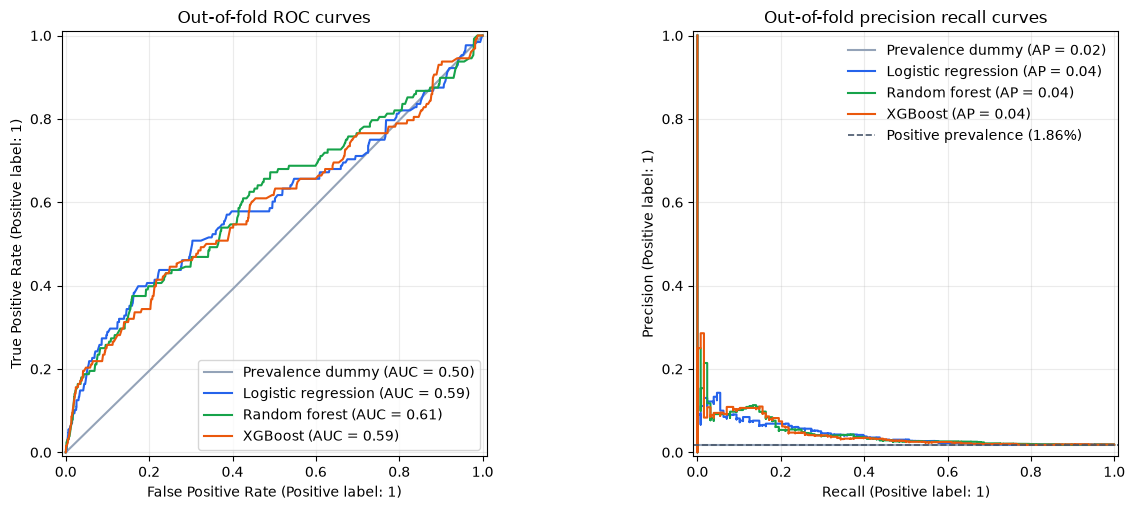

In [6]:
COLORS = {"dummy": "#94A3B8", "logistic": "#2563EB", "random_forest": "#16A34A", "xgboost": "#EA580C"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for model_name in estimators:
    probability_column = f"{model_name}_probability"
    RocCurveDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[0],
    )
    PrecisionRecallDisplay.from_predictions(
        oof_predictions["target"],
        oof_predictions[probability_column],
        name=MODEL_LABELS[model_name],
        curve_kwargs={"color": COLORS[model_name]},
        ax=axes[1],
    )

axes[0].set_title("Out-of-fold ROC curves")
axes[1].axhline(
    train["target"].mean(),
    color="#475569",
    linestyle="--",
    linewidth=1.2,
    label=f"Positive prevalence ({train['target'].mean():.2%})",
)
axes[1].set_title("Out-of-fold precision recall curves")
axes[1].legend(frameon=False)
for axis in axes:
    axis.grid(alpha=0.25)

fig.tight_layout()
CURVES_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(CURVES_PATH, dpi=160, bbox_inches="tight")
plt.show()


### Inspect Logistic Regression coefficients



In [7]:
fitted_logistic = build_logistic_metadata_pipeline()
fitted_logistic.fit(train[FEATURE_COLUMNS], train["target"])

feature_names = fitted_logistic.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.DataFrame(
    {
        "encoded_feature": feature_names,
        "coefficient": fitted_logistic.named_steps["classifier"].coef_[0],
    }
)
coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()
coefficients = coefficients.sort_values("absolute_coefficient", ascending=False).reset_index(drop=True)
coefficients.head(15).round(4)


,encoded_feature,coefficient,absolute_coefficient
0,age_approx_75,1.2371,1.2371
1,sex_female,-1.1665,1.1665
2,age_approx_90,1.1201,1.1201
3,age_approx_35,-1.0348,1.0348
4,sex_male,-0.9356,0.9356
5,anatom_site_general_challenge_oral/genital,0.9217,0.9217
6,anatom_site_general_challenge_palms/soles,-0.9020,0.9020
7,age_approx_40,-0.8961,0.8961
8,age_approx_80,0.8133,0.8133
9,age_approx_25,-0.7395,0.7395


Positive coefficient: pushes the predicted malignancy probability upward.

Negative coefficient: pushes it downward.

Larger absolute coefficient: has a larger influence on the model’s log-odds.

## Takeaways

1. The prevalence dummy establishes the no-skill reference at **0.0184 average precision**.
2. Logistic regression remains the clearest interpretable baseline at **0.594 ROC-AUC** and **0.0418 average precision**.
3. Random forest performs best overall at **0.606 ROC-AUC** and **0.0443 average precision**, although the gain over logistic regression is modest.
4. XGBoost reaches **0.0439 average precision** but a lower **0.590 ROC-AUC**; none of the learned models is consistently strongest across every fold.
5. The labelled test subset remains untouched. Image and fusion models should use the same folds and metrics before one final test-set evaluation.
